# Plotting in myeda

<a id="contents"></a>

## Contents

Click an example to jump to it. Run the setup cell before running individual examples.

- [auto_plot arguments](#auto-plot-arguments)
- [Setup and example data](#setup-and-example-data)

**Automatic plots**

- [One numeric column](#one-numeric-column)
- [One categorical column](#one-categorical-column)
- [Two numeric columns](#two-numeric-columns)
- [Category and number: totals](#category-and-number-totals)
- [Category and number: change the aggregation](#category-and-number-change-the-aggregation)
- [Category and number: count observations](#category-and-number-count-observations)
- [Category and number: distributions](#category-and-number-distributions)
- [Two categorical columns](#two-categorical-columns)
- [Datetime and number](#datetime-and-number)
- [Two numbers and a category](#two-numbers-and-a-category)
- [One number and two categories: grouped bars](#one-number-and-two-categories-grouped-bars)
- [One number and two categories: stacked totals](#one-number-and-two-categories-stacked-totals)
- [More categories: heatmap](#more-categories-heatmap)

**[Standalone plotting functions](#standalone-plotting-functions)**

- [`plot_scatter`: optional category grouping](#plotscatter-optional-category-grouping)
- [`plot_bar`: pre-aggregated heights](#plotbar-preaggregated-heights)
- [`plot_boxplot`: compare distributions](#plotboxplot-compare-distributions)
- [`plot_histogram`: histogram and density](#plothistogram-histogram-and-density)
- [`plot_grouped_bar`: aggregate by two categories](#plotgroupedbar-aggregate-by-two-categories)
- [`plot_stacked_bar`: contributions to totals](#plotstackedbar-contributions-to-totals)
- [`plot_heatmap`: select a heatmap explicitly](#plotheatmap-select-a-heatmap-explicitly)
- [Customize a returned figure](#customize-a-returned-figure)


<a id="auto-plot-arguments"></a>

### `auto_plot()`

[Back to contents](#contents)

Choose a plot from the types of one, two, or three DataFrame columns.
Run the cells in order to see each argument combination.

```python
auto_plot(df, x_col, y_col=None, other_cols=None,
          agg="sum", additive=False, distribution=False)
```

- `df`: the input DataFrame.
- `x_col`: a column name. For mixed types, put the category or datetime on x and the number on y.
- `y_col`: optional second column; omit it for a distribution or category counts.
- `other_cols`: an optional third column name, passed as a **string**. Lists are not implemented yet.
- `agg`: aggregation such as `"sum"`, `"mean"`, `"max"`, or `"count"` for numeric values grouped by categories or dates. Default: `"sum"`.
- `additive`: with one numeric and two low-cardinality categorical columns, `True` selects stacked bars; `False` selects grouped bars.
- `distribution`: with a category on x and a number on y, `True` selects a box plot instead of aggregating. Default: `False`.

`auto_plot` displays its plot directly. Use the standalone functions below when you want to select a plot explicitly or access its Matplotlib figure and axes. Extra styling keywords are currently not forwarded by `auto_plot`.

<a id="setup-and-example-data"></a>

### Setup and example data

[Back to contents](#contents)

These examples use the repository's `data/sales_by_region.csv`, so no dataset download is needed.
The setup works with the notebook launched from either the repository root or `documentation/`.

In [1]:
import seaborn as sns
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

repo_root = Path.cwd()
if not (repo_root / "src" / "auto_plot.py").is_file():
    repo_root = repo_root.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from src.auto_plot import (
    auto_plot,
    plot_scatter,
    plot_bar,
    plot_boxplot,
    plot_histogram,
    plot_grouped_bar,
    plot_stacked_bar,
    plot_heatmap,
)

sns.set_theme(style="whitegrid", rc={"figure.figsize": (8, 4)})
df = pd.read_csv(repo_root / "data" / "sales_by_region.csv", parse_dates=["date"])
categorical_columns = ["region", "product", "city", "sales_channel"]
df[categorical_columns] = df[categorical_columns].astype("category")

In [2]:
# Numeric: units_sold, revenue, customer_rating
# Categories: region, product, city, sales_channel; datetime: date
display(df.head())

,date,region,product,units_sold,revenue,customer_rating,city,sales_channel
0,2025-01-15,North,Essentials,128,3840.0,4.2,Austin,Online
1,2025-01-15,South,Essentials,96,2880.0,4.0,Boston,Store
2,2025-01-15,East,Essentials,112,3360.0,4.4,Chicago,Partner
3,2025-01-15,West,Essentials,104,3120.0,4.1,Denver,Mobile
4,2025-01-15,North,Premium,66,3960.0,4.5,Miami,Wholesale


### Automatic plots

<a id="one-numeric-column"></a>

#### One numeric column

[Back to contents](#contents)

Omit `y_col` to show a histogram and a density estimate side by side.

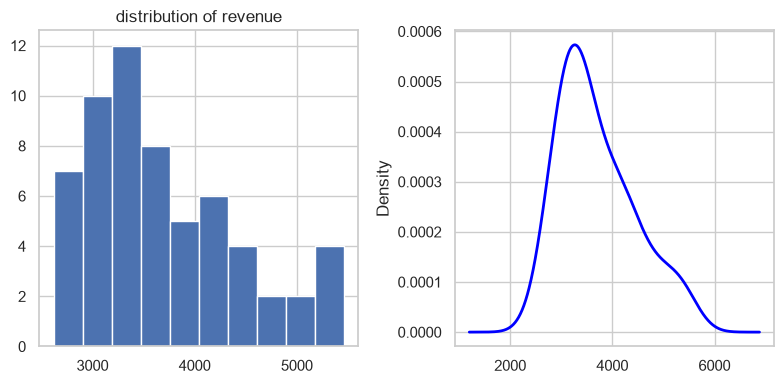

In [3]:
auto_plot(df=df, x_col="revenue")

<a id="one-categorical-column"></a>

#### One categorical column

[Back to contents](#contents)

Omitting `y_col` for a category counts its rows automatically.

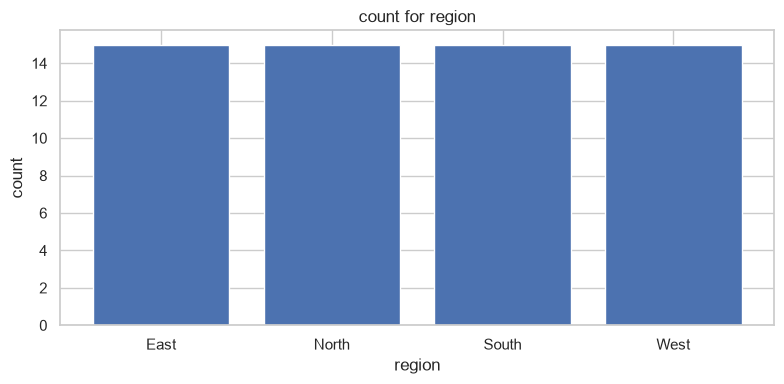

In [4]:
auto_plot(df=df, x_col="region")

<a id="two-numeric-columns"></a>

#### Two numeric columns

[Back to contents](#contents)

Two numeric columns select a scatter plot.

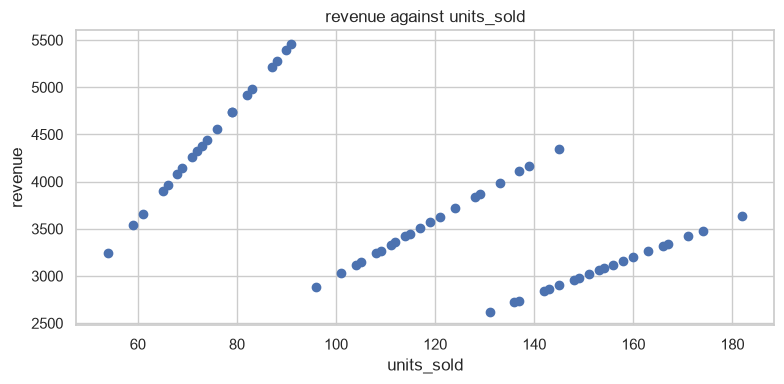

In [5]:
auto_plot(df=df, x_col="units_sold", y_col="revenue")

<a id="category-and-number-totals"></a>

#### Category and number: totals

[Back to contents](#contents)

The default `agg="sum"` adds the revenue within each region.

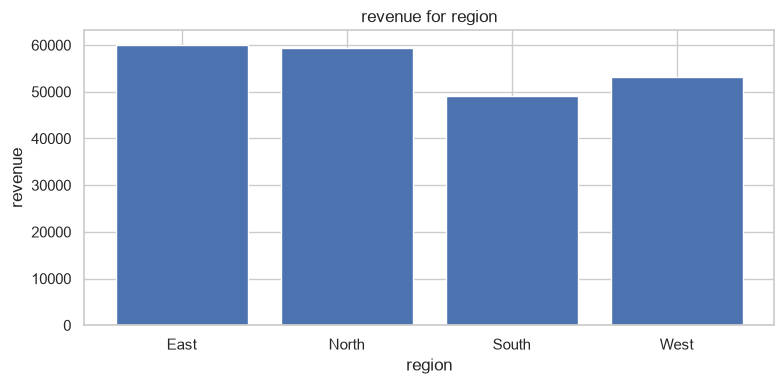

In [6]:
auto_plot(df=df, x_col="region", y_col="revenue")

<a id="category-and-number-change-the-aggregation"></a>

#### Category and number: change the aggregation

[Back to contents](#contents)

Compare average revenue with maximum revenue using the same columns.

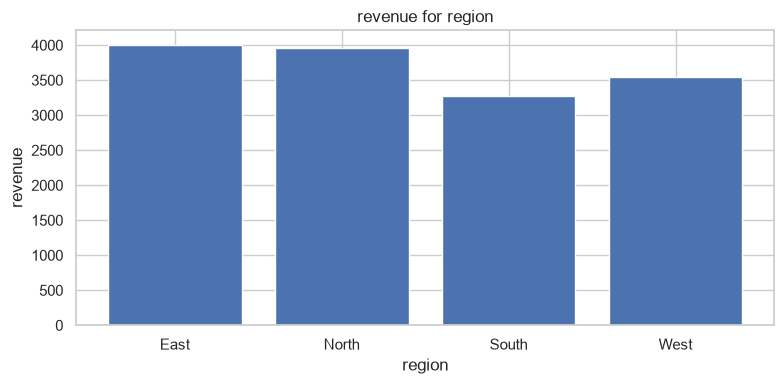

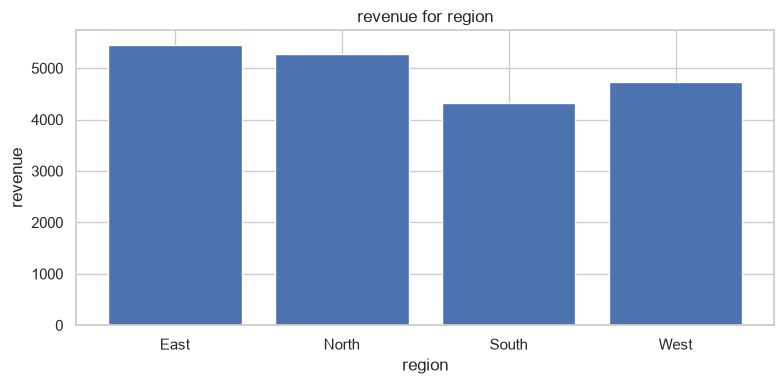

In [7]:
auto_plot(df=df, x_col="region", y_col="revenue", agg="mean")
auto_plot(df=df, x_col="region", y_col="revenue", agg="max")

<a id="category-and-number-count-observations"></a>

#### Category and number: count observations

[Back to contents](#contents)

`agg="count"` counts non-missing values in `y_col` for each category.

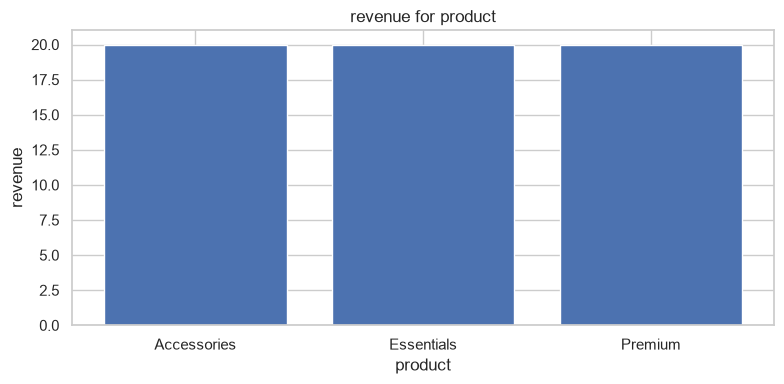

In [8]:
auto_plot(df=df, x_col="product", y_col="revenue", agg="count")

<a id="category-and-number-distributions"></a>

#### Category and number: distributions

[Back to contents](#contents)

`distribution=True` shows the spread, median, and outliers instead of a single aggregate per group.

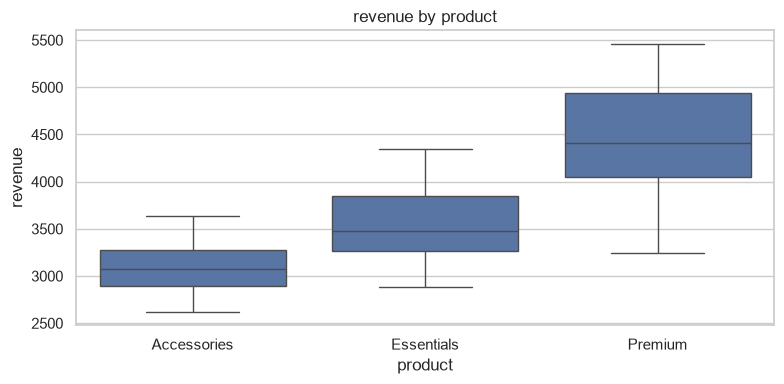

In [9]:
auto_plot(df=df, x_col="product", y_col="revenue", distribution=True)

<a id="two-categorical-columns"></a>

#### Two categorical columns

[Back to contents](#contents)

With two categories, the bars count each observed combination. `agg` does not change these counts.

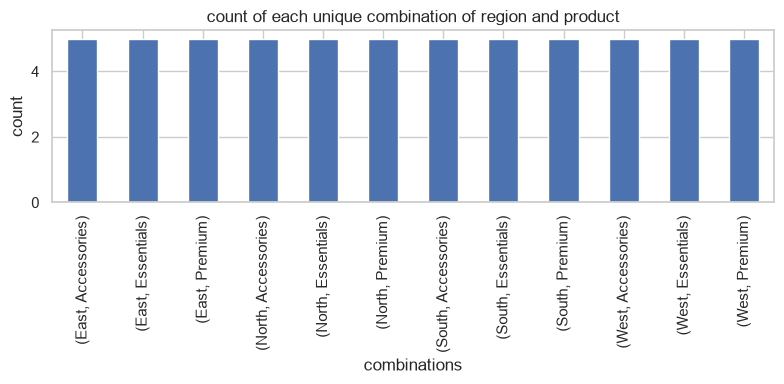

In [10]:
auto_plot(df=df, x_col="region", y_col="product")

<a id="datetime-and-number"></a>

#### Datetime and number

[Back to contents](#contents)

Datetime values on x are grouped by day; `agg` controls how the numeric values are combined. Here, `mean` shows the average revenue for each recorded date. The result is a scatter plot.

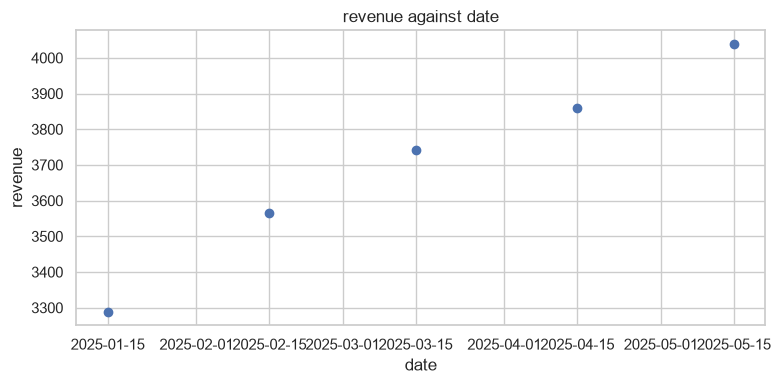

In [11]:
auto_plot(df=df, x_col="date", y_col="revenue", agg="mean")

<a id="two-numbers-and-a-category"></a>

#### Two numbers and a category

[Back to contents](#contents)

Pass a single column name to `other_cols` to color the scatter points by category.

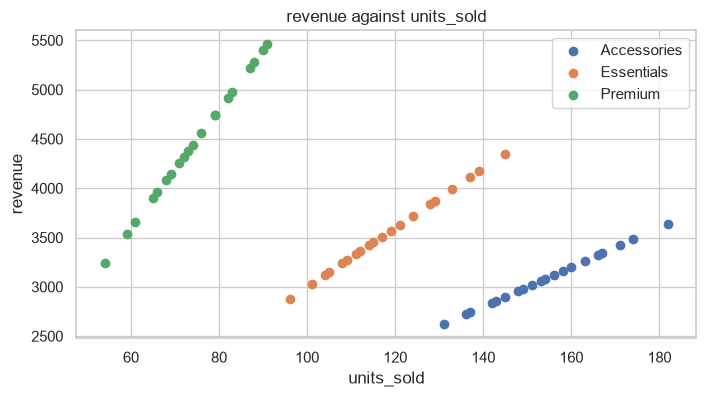

In [12]:
auto_plot(df=df, x_col="units_sold", y_col="revenue", other_cols="product")

<a id="one-number-and-two-categories-grouped-bars"></a>

#### One number and two categories: grouped bars

[Back to contents](#contents)

With at most 6 x categories and 5 additional categories, `additive=False` selects grouped bars. Here the bars compare average revenue.

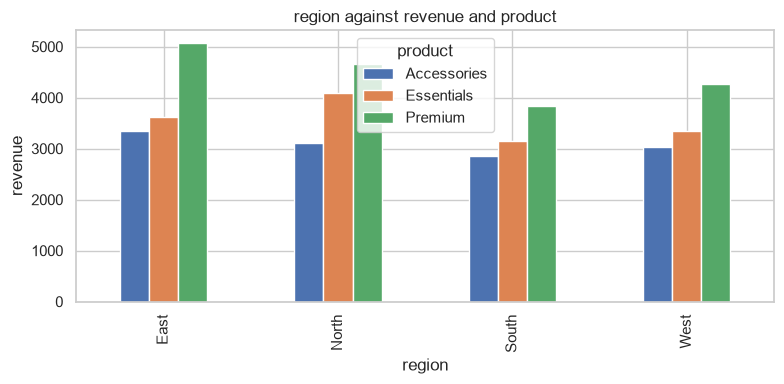

In [13]:
auto_plot(
    df=df,
    x_col="region",
    y_col="revenue",
    other_cols="product",
    agg="mean",
    additive=False,
)

<a id="one-number-and-two-categories-stacked-totals"></a>

#### One number and two categories: stacked totals

[Back to contents](#contents)

Use `additive=True` with `agg="sum"` to show how products contribute to each region's total revenue.

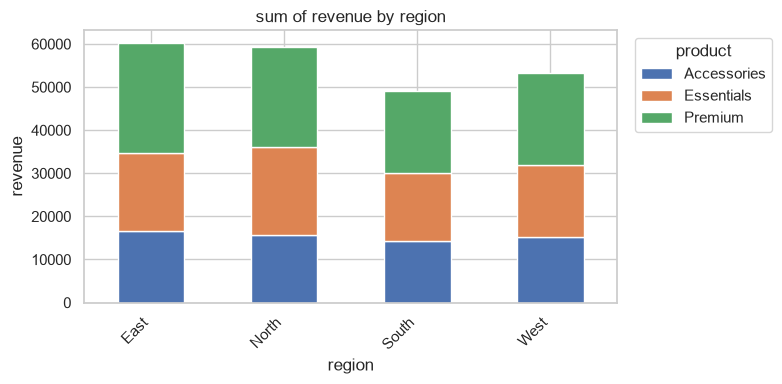

In [14]:
auto_plot(
    df=df,
    x_col="region",
    y_col="revenue",
    other_cols="product",
    agg="sum",
    additive=True,
)

<a id="more-categories-heatmap"></a>

#### More categories: heatmap

[Back to contents](#contents)

The 8 cities exceed the 6-category x threshold, so `auto_plot` selects a heatmap. It also selects a heatmap when `other_cols` has more than 5 categories, regardless of `additive`. Missing category combinations are filled with zero by the plotting function.

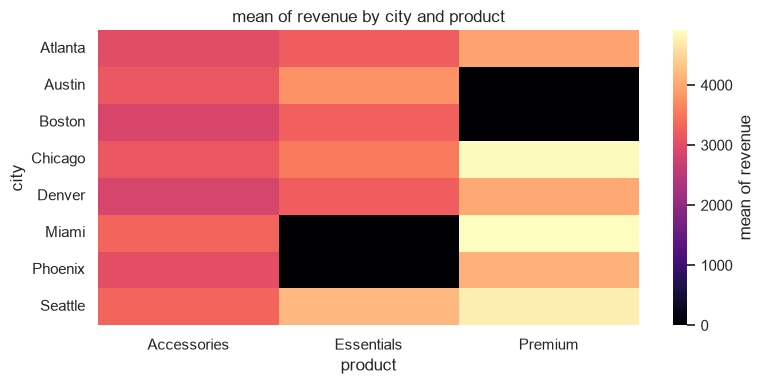

In [15]:
auto_plot(df=df, x_col="city", y_col="revenue", other_cols="product", agg="mean")

<a id="standalone-plotting-functions"></a>

### Standalone plotting functions

[Back to contents](#contents)

Call these functions directly to choose the plot yourself. They return `(fig, ax)`, except
`plot_histogram`, which returns only `fig`. All of them also call `plt.show()`.

Unlike `auto_plot`, `plot_bar` expects the bar heights to be prepared already.
The grouped, stacked, and heatmap functions aggregate the raw rows themselves when a third column is supplied.

<a id="plotscatter-optional-category-grouping"></a>

#### `plot_scatter`: optional category grouping

[Back to contents](#contents)

Use `other_col` (singular) here, compared with `other_cols` in `auto_plot`. Omit it for an ungrouped scatter.

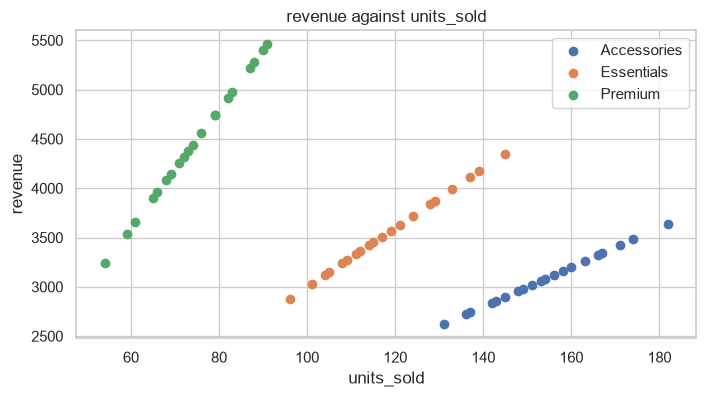

In [16]:
fig, ax = plot_scatter(df=df, x_col="units_sold", y_col="revenue", other_col="product")

<a id="plotbar-preaggregated-heights"></a>

#### `plot_bar`: pre-aggregated heights

[Back to contents](#contents)

Prepare one row per region before plotting. This example uses mean revenue.

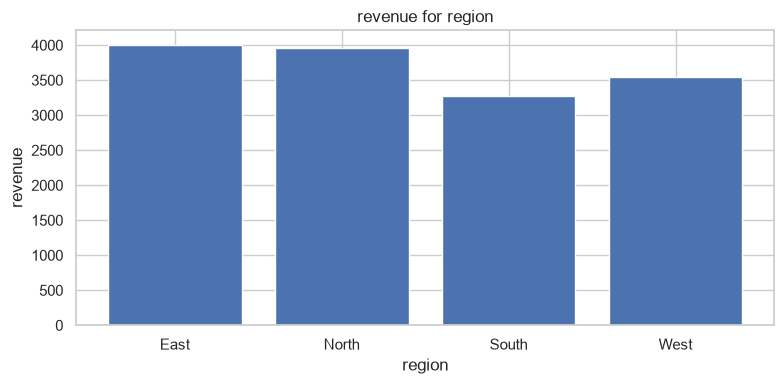

In [17]:
revenue_by_region = df.groupby("region", observed=True)["revenue"].mean().reset_index()
fig, ax = plot_bar(df=revenue_by_region, x_col="region", y_col="revenue")

<a id="plotboxplot-compare-distributions"></a>

#### `plot_boxplot`: compare distributions

[Back to contents](#contents)

Pass raw observations so each box represents the distribution of revenue for a product.

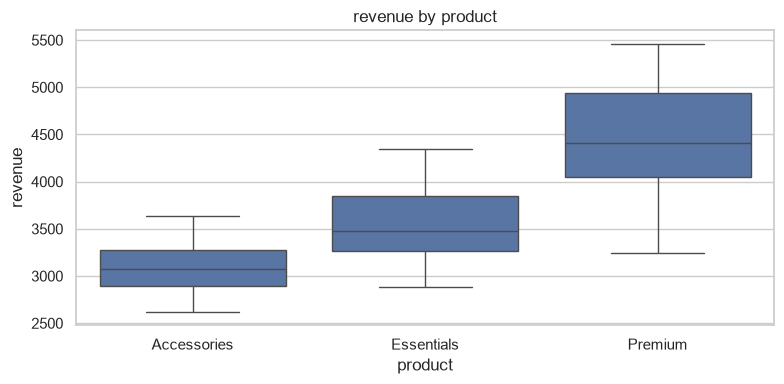

In [18]:
fig, ax = plot_boxplot(df=df, x_col="product", y_col="revenue")

<a id="plothistogram-histogram-and-density"></a>

#### `plot_histogram`: histogram and density

[Back to contents](#contents)

This function creates two axes and returns their shared figure.

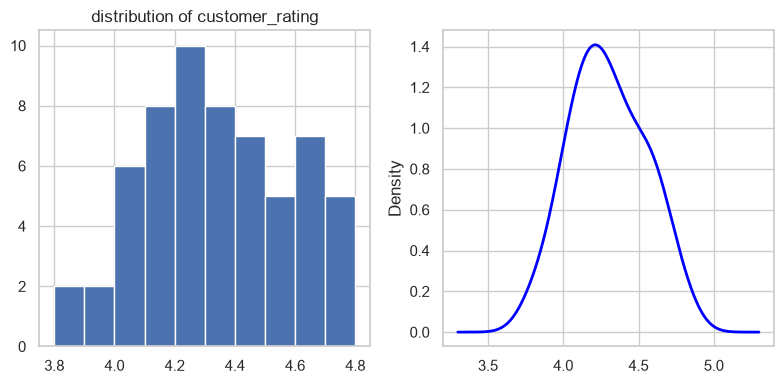

In [19]:
fig = plot_histogram(df=df, x_col="customer_rating")

<a id="plotgroupedbar-aggregate-by-two-categories"></a>

#### `plot_grouped_bar`: aggregate by two categories

[Back to contents](#contents)

With `other_col`, choose the aggregation for each region/product combination. Without it, the function counts x/y category combinations.

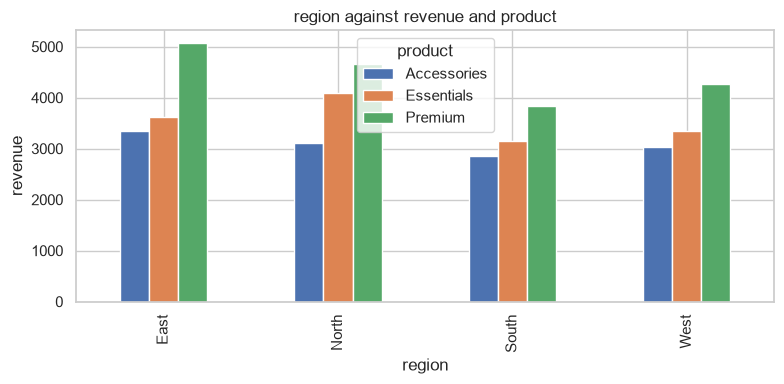

In [20]:
fig, ax = plot_grouped_bar(
    df=df, x_col="region", y_col="revenue", agg="mean", other_col="product"
)

<a id="plotstackedbar-contributions-to-totals"></a>

#### `plot_stacked_bar`: contributions to totals

[Back to contents](#contents)

Stack each product's summed revenue within its region.

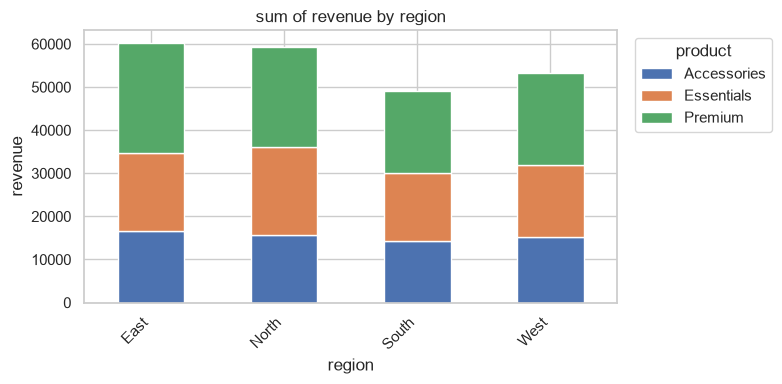

In [21]:
fig, ax = plot_stacked_bar(
    df=df, x_col="region", y_col="revenue", other_col="product", agg="sum"
)

<a id="plotheatmap-select-a-heatmap-explicitly"></a>

#### `plot_heatmap`: select a heatmap explicitly

[Back to contents](#contents)

A direct call works even for a small number of categories that would normally produce bars in `auto_plot`. Colors represent average revenue.

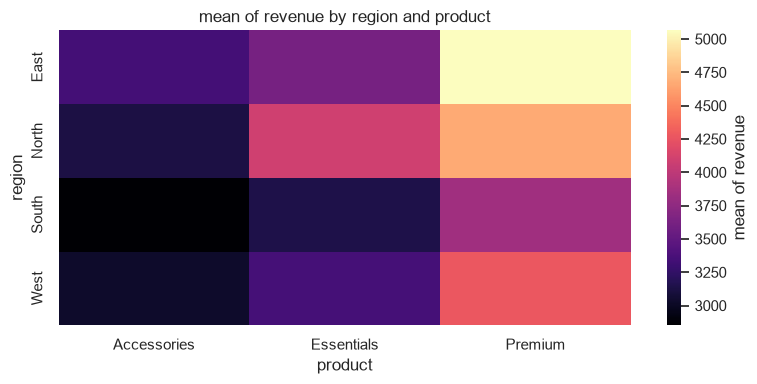

In [22]:
fig, ax = plot_heatmap(
    df=df, x_col="region", y_col="revenue", other_col="product", agg="mean"
)

<a id="customize-a-returned-figure"></a>

#### Customize a returned figure

[Back to contents](#contents)

The standalone functions expose Matplotlib's figure and axes. After changing them,
display the figure again to see the updated labels and formatting.

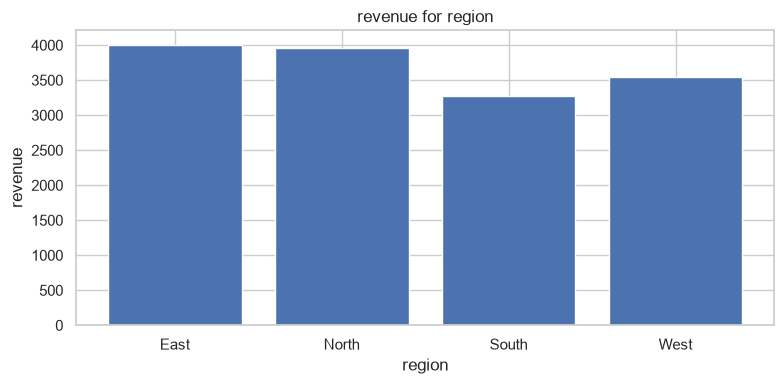

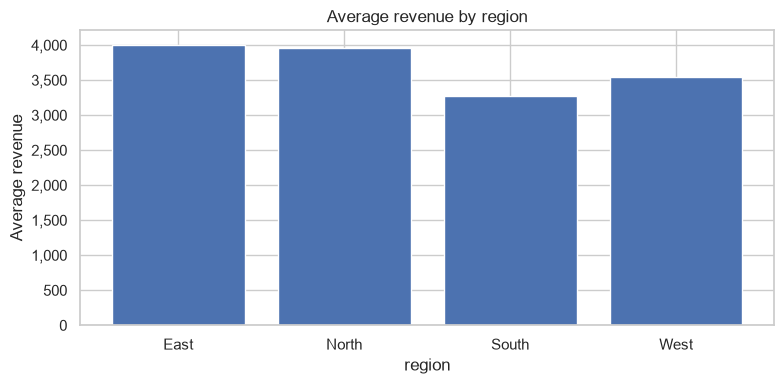

In [23]:
fig, ax = plot_bar(df=revenue_by_region, x_col="region", y_col="revenue")
ax.set(title="Average revenue by region", ylabel="Average revenue")
ax.yaxis.set_major_formatter("{x:,.0f}")
fig.tight_layout()
display(fig)